Загрузка данных...

--- Исходная информация о датасете ---
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   longitude           20640 non-null  float64 
 1   latitude            20640 non-null  float64 
 2   housing_median_age  20640 non-null  int64   
 3   total_rooms         20640 non-null  int64   
 4   total_bedrooms      20433 non-null  float64 
 5   population          20640 non-null  int64   
 6   households          20640 non-null  int64   
 7   median_income       20640 non-null  float64 
 8   median_house_value  20640 non-null  int64   
 9   ocean_proximity     20640 non-null  category
dtypes: category(1), float64(4), int64(5)
memory usage: 1.4 MB
None


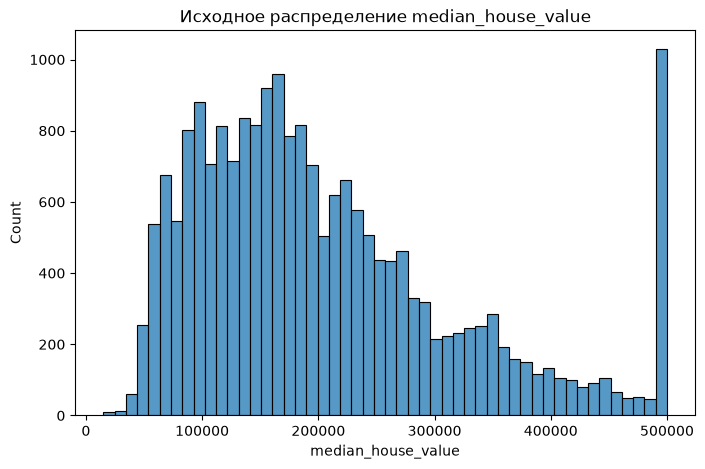

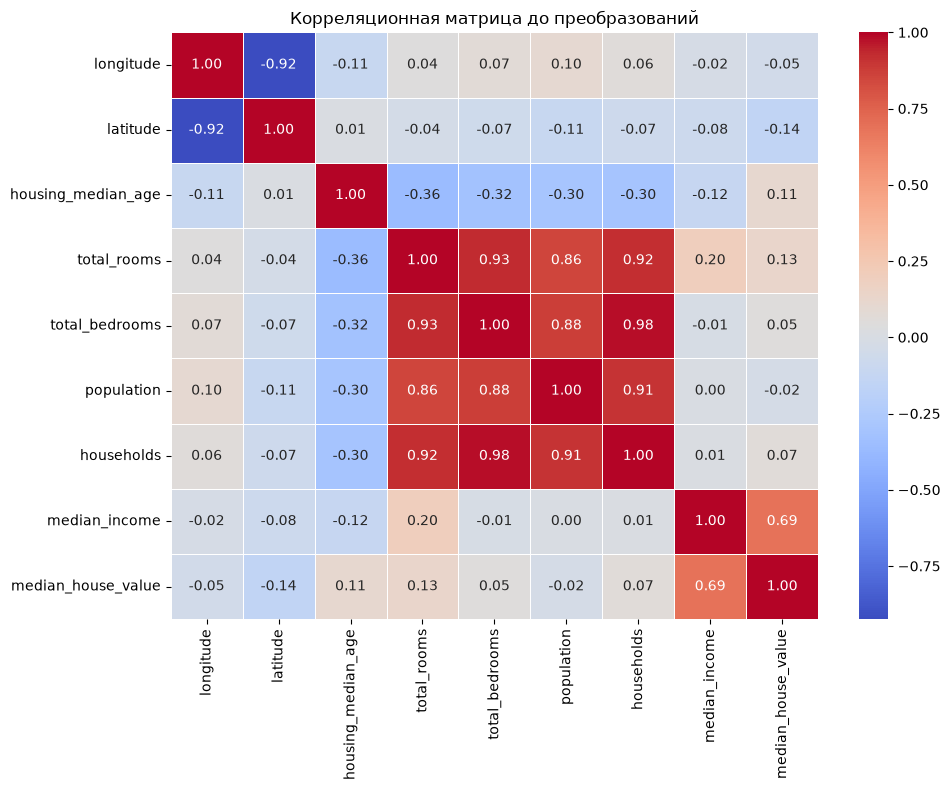


Создание новых признаков...

--- Статистики новых признаков ---
       rooms_per_household  bedrooms_per_room  population_per_household
count         20433.000000       20433.000000              20433.000000
mean              5.431344           0.213039                  3.071533
std               2.482946           0.057983                 10.438269
min               0.846154           0.100000                  0.692308
25%               4.441441           0.175427                  2.429032
50%               5.230769           0.203162                  2.817582
75%               6.052381           0.239821                  3.281513
max             141.909091           1.000000               1243.333333

--- Итоговая форма датасета ---
(20433, 13)

--- Итоговая корреляционная матрица ---


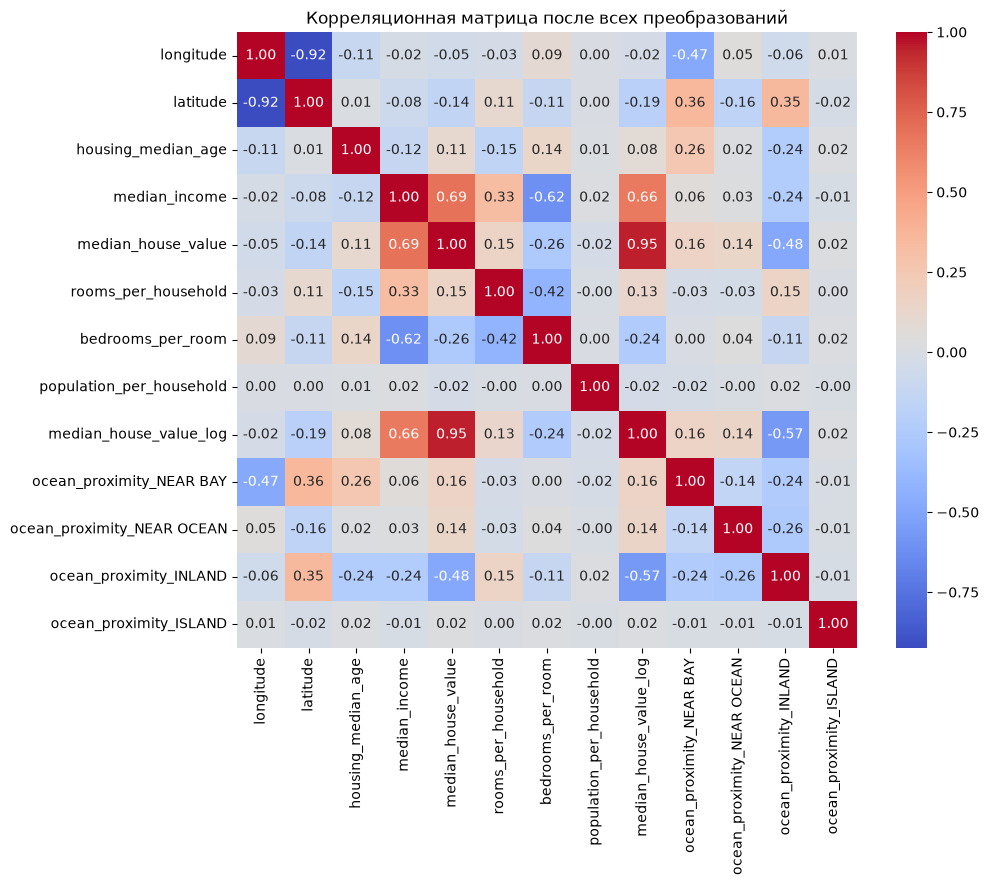


--- Проверка масштабирования ---
Среднее по признакам (train): 
[-0.  0.  0. -0.  0.  0.  0.  0. -0.  0. -0.]

Std отклонение по признакам (train): 
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
 СРАВНЕНИЕ МОДЕЛЕЙ (метрики рассчитаны для log(median_house_value))
Linear Regression  | Test RMSE: 0.3471 | CV RMSE: 0.3415
Ridge              | Test RMSE: 0.3471 | CV RMSE: 0.3413 (лучший alpha: 1.0000)
Lasso              | Test RMSE: 0.3539 | CV RMSE: 0.3494 (лучший alpha: 0.0100)
ElasticNet         | Test RMSE: 0.3473 | CV RMSE: 0.3426 (лучший alpha: 0.0100)

=== Важность признаков (Ridge) ===
                   Признак  Коэффициент
             median_income     0.336762
         bedrooms_per_room     0.064274
       rooms_per_household     0.042569
        housing_median_age     0.017676
    ocean_proximity_ISLAND     0.010650
  ocean_proximity_NEAR BAY    -0.004707
ocean_proximity_NEAR OCEAN    -0.006613
  population_per_household    -0.015667
    ocean_proximity_INLAND    -0.138445
              

/tmp/ipykernel_3645/2459522743.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coefficients, x='Коэффициент', y='Признак', palette='coolwarm')


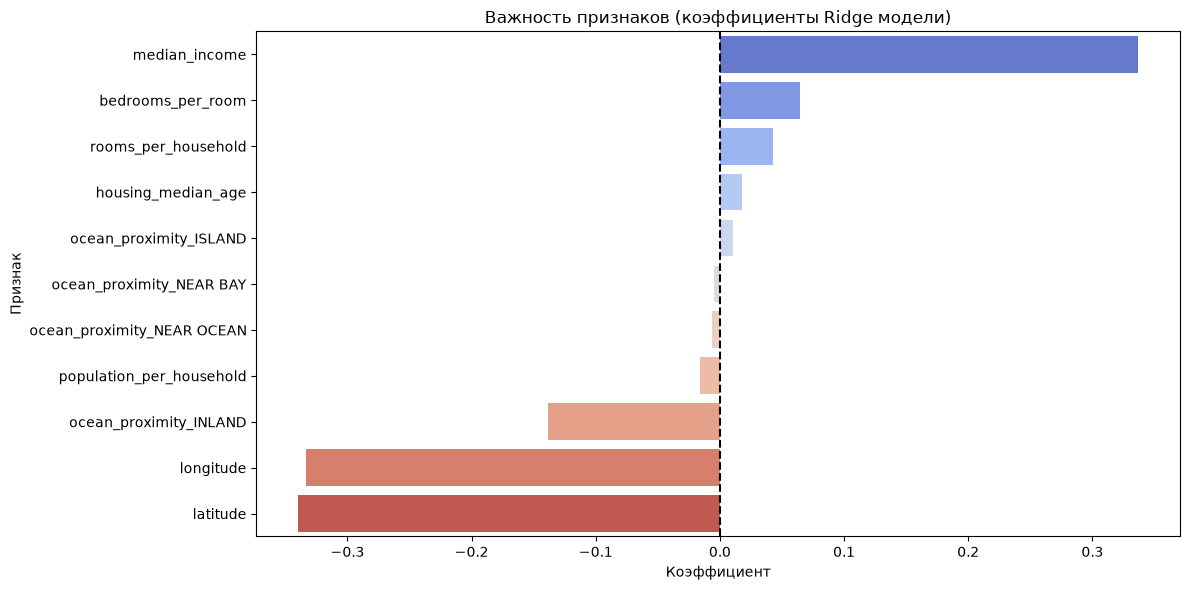

ДЕМОНСТРАЦИЯ РАБОТЫ МОДЕЛИ
Средняя абсолютная ошибка (MAE): $55,419.35
Среднеквадратичная ошибка (RMSE): $92,147.69
Это означает, что в среднем модель ошибается примерно на $55,419 при оценке дома.

--- Пример предсказаний на первых 10 объектах тестовой выборки ---
 Реальная стоимость ($)  Предсказанная моделью ($)  Разница ($)
               245800.0                  188958.66    -56841.34
               137900.0                  139233.54      1333.54
               218200.0                  181477.44    -36722.56
               220800.0                  172202.15    -48597.85
               170500.0                  156297.13    -14202.87
                75000.0                   95790.95     20790.95
               269400.0                  277793.36      8393.36
               228900.0                  229289.03       389.03
               500001.0                  415452.94    -84548.06
                80800.0                   77494.98     -3305.02


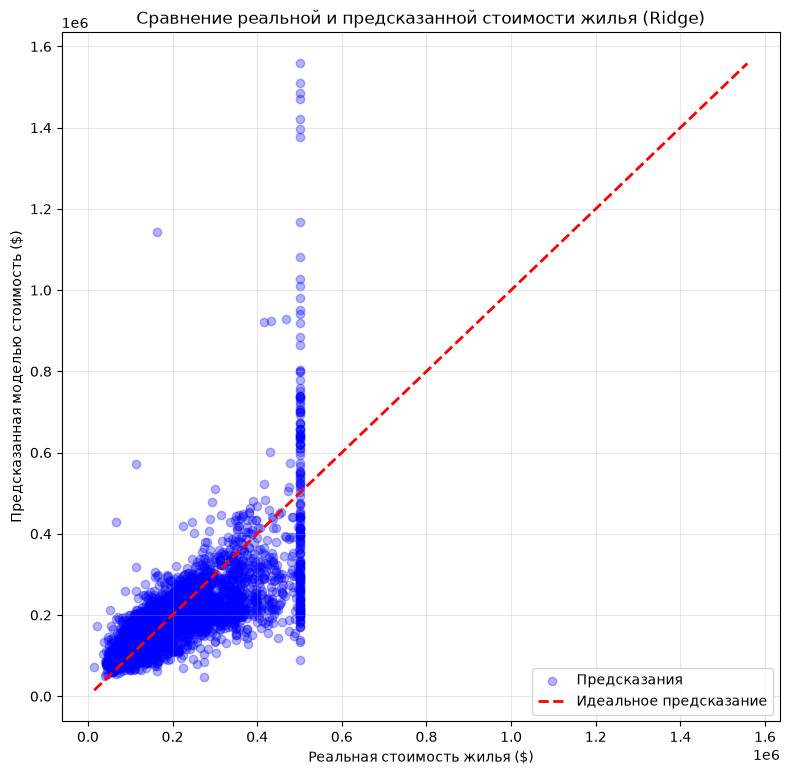

ВИЗУАЛИЗАЦИЯ В ЛОГАРИФМИЧЕСКОМ МАСШТАБЕ

RMSE (в логарифмах): 0.3471
MAE (в логарифмах): 0.2657


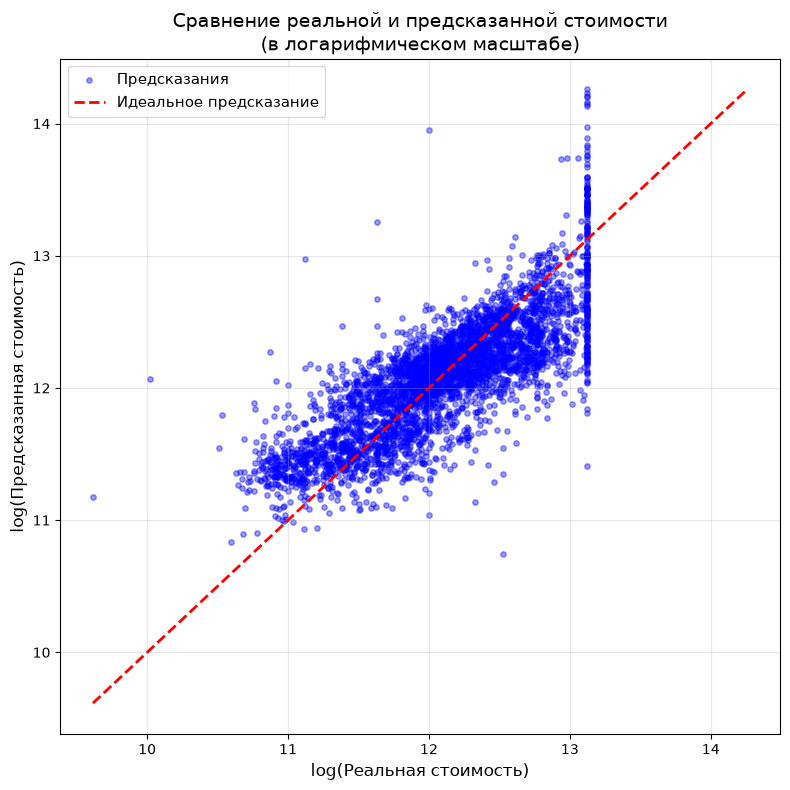


Средняя ошибка (bias): -0.0050
Стандартное отклонение ошибок (std): 0.3471


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error

 
# ШАГ 1: Загрузка данных
 
print("Загрузка данных...")
data = fetch_openml(data_id=43939, as_frame=True, parser="auto")
df = data.frame


# ШАГ 2: Первичный EDA

print("\n--- Исходная информация о датасете ---")
print(df.info())

plt.figure(figsize=(8, 5))
sns.histplot(df['median_house_value'], bins=50)
plt.title('Исходное распределение median_house_value')
plt.show()

plt.figure(figsize=(10, 8))
corr_initial = df.select_dtypes(include=['number']).corr()
sns.heatmap(corr_initial, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Корреляционная матрица до преобразований')
plt.tight_layout()
plt.show()


# ШАГ 3: Инженерия признаков и борьба с мультиколлинеарностью

# Сразу удаляем пропуски (их было ~200 в total_bedrooms)
df = df.dropna().reset_index(drop=True)

print("\nСоздание новых признаков...")
# Создаем осмысленные отношения
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

# Логарифмируем целевую переменную для борьбы с выбросами
df['median_house_value_log'] = np.log(df['median_house_value'])

# Удаляем старые мультиколлинеарные признаки
df = df.drop(['total_rooms', 'total_bedrooms', 'population', 'households'], axis=1)

print("\n--- Статистики новых признаков ---")
print(df[['rooms_per_household', 'bedrooms_per_room', 'population_per_household']].describe())


# ШАГ 4: One-Hot Encoding категориальных признаков

df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True, dtype=int)


# ШАГ 5: Финальная проверка признаков

print("\n--- Итоговая форма датасета ---")
print(df.shape) 

print("\n--- Итоговая корреляционная матрица ---")
plt.figure(figsize=(10, 8))
corr_final = df.select_dtypes(include=['number']).corr()
sns.heatmap(corr_final, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляционная матрица после всех преобразований')
plt.show()


# ШАГ 6: Разделение данных и Масштабирование

X = df.drop(['median_house_value', 'median_house_value_log'], axis=1)
y = df['median_house_value_log']

# Делим на train (80%) и test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Масштабируем признаки
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n--- Проверка масштабирования ---")
print(f"Среднее по признакам (train): \n{X_train_scaled.mean(axis=0).round(5)}")
print(f"\nStd отклонение по признакам (train): \n{X_train_scaled.std(axis=0).round(5)}")


# ШАГ 7: Обучение и сравнение моделей

print(" СРАВНЕНИЕ МОДЕЛЕЙ (метрики рассчитаны для log(median_house_value))")

# Словарь с моделями. CV-версии сами найдут лучший alpha из предложенного списка!
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0]),
    "Lasso": LassoCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], random_state=42, max_iter=10000),
    "ElasticNet": ElasticNetCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], l1_ratio=[0.1, 0.5, 0.9], random_state=42, max_iter=10000)
}

results = {}

for name, model in models.items():
    # Обучаем модель
    model.fit(X_train_scaled, y_train)
    
    # Делаем предсказания на тесте
    y_pred = model.predict(X_test_scaled)
    
    # Считаем RMSE на тесте
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
    
    # Считаем RMSE через кросс-валидацию на train (5 фолдов)
    # scoring='neg_mean_squared_error' возвращает отрицательное значение, поэтому берем корень из -cv_scores
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='neg_mean_squared_error')
    rmse_cv = np.sqrt(-cv_scores.mean())
    
    # Сохраняем результаты
    results[name] = {"Test RMSE": rmse_test, "CV RMSE": rmse_cv}
    
    # Выводим результат + лучший alpha (если модель его подобрала)
    best_alpha_info = ""
    if hasattr(model, 'alpha_'):
        best_alpha_info = f" (лучший alpha: {model.alpha_:.4f})"
        
    print(f"{name:18} | Test RMSE: {rmse_test:.4f} | CV RMSE: {rmse_cv:.4f}{best_alpha_info}")


# Берём лучшую модель (Ridge)
best_model = models["Ridge"]

# Получаем коэффициенты
coefficients = pd.DataFrame({
    'Признак': X.columns,
    'Коэффициент': best_model.coef_
})
coefficients = coefficients.sort_values('Коэффициент', ascending=False)

print("\n=== Важность признаков (Ridge) ===")
print(coefficients.to_string(index=False))

# Визуализация
plt.figure(figsize=(12, 6))
sns.barplot(data=coefficients, x='Коэффициент', y='Признак', palette='coolwarm')
plt.title('Важность признаков (коэффициенты Ridge модели)')
plt.axvline(x=0, color='black', linestyle='--')
plt.tight_layout()
plt.show()


# ШАГ 8: Демонстрация правильности предсказаний (в долларах)
print("ДЕМОНСТРАЦИЯ РАБОТЫ МОДЕЛИ")

# 1. Делаем предсказание логарифмов цен для тестовой выборки лучшей моделью (Ridge)
y_pred_log = best_model.predict(X_test_scaled)

# 2. Обратное преобразование: переводим логарифмы обратно в реальные доллары
y_test_actual = np.exp(y_test)         # Реальные цены из тестовой выборки
y_pred_actual = np.exp(y_pred_log)     # Цены, предсказанные моделью

# 3. Считаем ошибки уже в реальных долларах
rmse_dollars = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
mae_dollars = np.mean(np.abs(y_test_actual - y_pred_actual)) # Средняя абсолютная ошибка

print(f"Средняя абсолютная ошибка (MAE): ${mae_dollars:,.2f}")
print(f"Среднеквадратичная ошибка (RMSE): ${rmse_dollars:,.2f}")
print("Это означает, что в среднем модель ошибается примерно на ${:,.0f} при оценке дома.".format(mae_dollars))

# 4. Создаем таблицу для наглядного сравнения
comparison_df = pd.DataFrame({
    'Реальная стоимость ($)': y_test_actual.values.round(2),
    'Предсказанная моделью ($)': y_pred_actual.round(2),
    'Разница ($)': (y_pred_actual - y_test_actual.values).round(2)
})

print("\n--- Пример предсказаний на первых 10 объектах тестовой выборки ---")
print(comparison_df.head(10).to_string(index=False))

# 5. Визуализация: График "Реальная цена и предсказанная"
plt.figure(figsize=(8, 8))
plt.scatter(y_test_actual, y_pred_actual, alpha=0.3, color='blue', label='Предсказания')

# Рисуем идеальную диагональ (если бы модель предсказывала со 100% точностью)
max_val = max(y_test_actual.max(), y_pred_actual.max())
min_val = min(y_test_actual.min(), y_pred_actual.min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Идеальное предсказание')

plt.xlabel('Реальная стоимость жилья ($)')
plt.ylabel('Предсказанная моделью стоимость ($)')
plt.title('Сравнение реальной и предсказанной стоимости жилья (Ridge)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ШАГ 9: Визуализация в логарифмическом масштабе
print("ВИЗУАЛИЗАЦИЯ В ЛОГАРИФМИЧЕСКОМ МАСШТАБЕ")

# Метрики в логарифмах
print(f"\nRMSE (в логарифмах): {results['Ridge']['Test RMSE']:.4f}")
print(f"MAE (в логарифмах): {np.mean(np.abs(y_test - y_pred_log)):.4f}")

# График Реальная и Предсказанная цена (в логарифмах)
plt.figure(figsize=(8, 8))

# Рисуем точки
plt.scatter(y_test, y_pred_log, alpha=0.4, color='blue', label='Предсказания', s=15)

# Диагональ идеального предсказания (y = x)
min_val = min(y_test.min(), y_pred_log.min())
max_val = max(y_test.max(), y_pred_log.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Идеальное предсказание')

plt.xlabel('log(Реальная стоимость)', fontsize=12)
plt.ylabel('log(Предсказанная стоимость)', fontsize=12)
plt.title('Сравнение реальной и предсказанной стоимости\n(в логарифмическом масштабе)', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

errors_log = y_pred_log - y_test

print(f"\nСредняя ошибка (bias): {errors_log.mean():.4f}")
print(f"Стандартное отклонение ошибок (std): {errors_log.std():.4f}")

